# Лекція 5. Локальний деплоймент і оптимізація моделей

Демо до лекції. Усі моделі в цьому ноутбуці запускаються **локально** через [Ollama](https://ollama.com), їх використання відбувається через HTTP-запити.

## 0. Налаштування середовища

### 0.0. Імпортуємо бібліотеки

In [ ]:
import json
import subprocess
import sys
import time
import urllib.request

OLLAMA_URL = "http://localhost:11434"

### 0.1. Встановлюємо й запускаємо Ollama

Локально цю клітинку можна просто виконати: вона нічого не зробить.

In [ ]:
IN_COLAB = "google.colab" in sys.modules
print("Running in Colab:", IN_COLAB)

if IN_COLAB:
    !sudo apt-get -qq install -y zstd > /dev/null
    !curl -fsSL https://ollama.com/install.sh | sh
    subprocess.Popen(["ollama", "serve"], stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)
    time.sleep(5)

Running in Colab: True
>>> Cleaning up old version at /usr/local/lib/ollama
>>> Installing ollama to /usr/local
>>> Downloading ollama-linux-amd64.tar.zst
######################################################################## 100.0%
>>> Adding ollama user to video group...
>>> Adding current user to ollama group...
>>> Creating ollama systemd service...
>>> The Ollama API is now available at 127.0.0.1:11434.
>>> Install complete. Run "ollama" from the command line.


### 0.2. Перевіряємо, що Ollama працює

Ollama — це HTTP-сервер на порту 11434. Функція `ollama()` надсилає йому запит і повертає відповідь як словник Python; якщо сервер працює, побачимо його версію.

In [ ]:
def ollama(path, body=None, timeout=900):
    """POST-запит до Ollama (або GET, якщо body=None); повертає розібраний JSON."""
    data = json.dumps(body).encode() if body is not None else None
    req = urllib.request.Request(OLLAMA_URL + path, data=data, headers={"Content-Type": "application/json"})
    with urllib.request.urlopen(req, timeout=timeout) as resp:
        return json.load(resp)


print("Ollama version:", ollama("/api/version")["version"])

Ollama version: 0.40.16


## 1. Base, Instruct і Thinking

Порівнюємо три поведінки однієї й тієї самої моделі Qwen3 1.7B:
- **Base-модель** пройшла лише попереднє тренування: вона вміє передбачати наступний токен в інтернет-текстах, але не вміє відповідати на питання як асистент.
- **Instruct-модель** додатково донавчили на прикладах «інструкція → відповідь» у форматі діалогу.
- **Thinking** — режим, у якому Instruct-модель перед відповіддю генерує ланцюжок міркувань.

### 1.0. Завантажуємо моделі

Беремо одну й ту саму модель Qwen3 1.7B у двох версіях:
- **Base** — [Qwen3-1.7B-Base](https://huggingface.co/Qwen/Qwen3-1.7B-Base) у форматі GGUF (Q4_K_M) з Hugging Face;
- **Instruct** — офіційна [qwen3:1.7b](https://ollama.com/library/qwen3) з каталогу Ollama; вона ж уміє працювати в режимі міркування.

Перше завантаження займає кілька хвилин.

In [ ]:
BASE_MODEL = "hf.co/mradermacher/Qwen3-1.7B-Base-GGUF:Q4_K_M"
INSTRUCT_MODEL = "qwen3:1.7b"

for m in (BASE_MODEL, INSTRUCT_MODEL):
    print("pull", m, "→", ollama("/api/pull", {"model": m, "stream": False})["status"])

pull hf.co/mradermacher/Qwen3-1.7B-Base-GGUF:Q4_K_M → success
pull qwen3:1.7b → success


### 1.1. Допоміжні функції

Нам вистачить двох ендпойнтів Ollama:
- `/api/generate` з `"raw": true` — передає моделі текст як є, **без chat template**;
- `/api/chat` — приймає список повідомлень і сам загортає їх у chat template моделі.

У Qwen3 режим міркування вмикається параметром `think`. З `think=True` модель спершу генерує ланцюжок міркувань (Ollama повертає його окремим полем `message.thinking`), а вже потім — відповідь. Функція `compare_thinking()` запускає запит в обох режимах і показує відповідь, кількість згенерованих токенів і час.

In [ ]:
def generate_raw(model, prompt, max_tokens=120):
    """Продовження тексту без chat template — так «бачить» запит Base-модель."""
    r = ollama("/api/generate", {
        "model": model, "prompt": prompt, "raw": True, "stream": False,
        "options": {"temperature": 0, "seed": 1, "num_predict": max_tokens},
    })
    return r["response"]


def chat(model, prompt, think=False, max_tokens=3000):
    """Один запит у форматі діалогу; think=True вмикає режим міркування."""
    return ollama("/api/chat", {
        "model": model, "messages": [{"role": "user", "content": prompt}],
        "think": think, "stream": False,
        "options": {"temperature": 0, "seed": 1, "num_predict": max_tokens},
    })


def compare_thinking(prompt):
    for think in (False, True):
        r = chat(INSTRUCT_MODEL, prompt, think=think)
        msg = r["message"]
        print(f"=== think={think} | токенів: {r['eval_count']} | генерація: {r['eval_duration'] / 1e9:.1f} с")
        if msg.get("thinking"):
            print(f"--- міркування ({len(msg['thinking'])} символів), початок:")
            print(msg["thinking"][:600], "…")
        print("--- відповідь:")
        print(msg["content"])
        print()

### 1.2. Base: модель просто продовжує текст

Поставимо Base- та Instruct-моделі однакове питання.

In [ ]:
QUESTION = "Яка столиця Франції?"

In [ ]:
print(generate_raw(BASE_MODEL, QUESTION))

 Як називається найбільша річка Франції? Як називається найбільша річка Франції, яка розташована в Північній Америці? Як називається найбільша річка Франції, яка розташована в Півдні Франції? Як називається найбільша р


Для Base-моделі «Яка столиця Франції?» схоже на початок списку питань вікторини — тож вона продовжує цей список, а не відповідає.

### 1.3. Instruct: модель відповідає на питання

In [ ]:
print(chat(INSTRUCT_MODEL, QUESTION)["message"]["content"])

Столиця Франції — це **Париж**.


### 1.4. Instruct проти Thinking: багатокрокова задача

In [ ]:
compare_thinking(
    "У кошику 3 яблука. Марія поклала туди ще 2 пакети по 4 яблука, "
    "а потім зʼїла 2 яблука. Скільки яблук у кошику?"
)

=== think=False | токенів: 252 | генерація: 2.0 с
--- відповідь:
Розглянемо ситуацію крок за кроком:

1. **У кошику 3 яблука.**  
2. **Марія поклала туди ще 2 пакети по 4 яблука.**  
   - Кожен пакет містить 4 яблука, тому:
     $$
     2 \text{ пакети} \times 4 \text{ яблука} = 8 \text{ яблука}
     $$
   - Значить, після додавання пакетів у кошик буде:
     $$
     3 + 8 = 11 \text{ яблука}
     $$
3. **Марія зʼїла 2 яблука.**  
   - Після з’ївання:
     $$
     11 - 2 = 9 \text{ яблука}
     $$

**Відповідь:**  
$$
\boxed{9}
$$

=== think=True | токенів: 569 | генерація: 4.6 с
--- міркування (1410 символів), початок:
Okay, let's see. So the problem is about Maria putting some apples in a basket and then eating some. Let me break it down step by step.

First, the basket starts with 3 apples. Then, Maria adds 2 packages, each containing 4 apples. So, I need to calculate how many apples she adds in total. Each package has 4 apples, and there are 2 packages. So that's 2 times 4, which i

Обидва режими відповідають правильно, але з міркуванням модель генерує в кілька разів більше токенів — а користувач бачить відповідь лише після них. Зверніть увагу: міркує модель англійською, хоча питання українською.

### 1.5. Міркування не гарантують правильності

In [ ]:
compare_thinking("Скільки разів літера «р» трапляється в слові «трансформер»?")

=== think=False | токенів: 227 | генерація: 1.8 с
--- відповідь:
Щоб визначити, скільки разів літера **«р»** трапляється в слові **«трансформер»**, зробимо так:

Слово: **трансформер**

Розбілем його на складні слова:

- **транс**  
- **формер**

Тепер зіштовхуємо літеру **«р»** в кожному з складних слів:

1. **транс** — не має літери «р»  
2. **формер** — має **1** відтінок «р» (відтінок «р» у слові **формер**)

Отже, літера **«р»** трапляється **1 раз** в слові **«трансформер»**.

**Відповідь: 1 раз.**

=== think=True | токенів: 659 | генерація: 5.4 с
--- міркування (1490 символів), початок:
Okay, let's see. The user is asking how many times the letter "р" appears in the word "трансформер". First, I need to make sure I know the correct spelling of the word. The word in question is "трансформер". Let me write it out: трансформер.

Now, I need to check each letter one by one. Let's start from the beginning. The first letter is "т" which is "t" in Ukrainian, but the question is about th

Правильна відповідь — 3 (т**р**ансфо**р**ме**р**), але мала модель помиляється в обох режимах. Чому так — подумайте самі (це питання до лабораторної роботи).

Спробуйте власні запити: де режим міркування справді допомагає, а де лише витрачає токени?

## 2. Квантизація з Quanto

Завантажимо ту саму модель у чотирьох варіантах — від оригінальних 16 біт до 2 біт — і подивимося, що квантизація змінює в памʼяті, швидкості та якості. Якість перевіримо трьома способами: перплексією, перекладом з автоматичними метриками й очима — на вільній генерації тексту.

**Quanto.** [Optimum Quanto](https://github.com/huggingface/optimum-quanto) — бібліотека квантизації від Hugging Face, один із бекендів [Optimum](https://huggingface.co/docs/optimum). У Transformers вона підключається через [`QuantoConfig`](https://huggingface.co/docs/transformers/quantization/quanto) і квантизує модель прямо під час завантаження, тому окремий файл з квантизованими вагами не потрібен. Квантизуються ваги лінійних шарів (`nn.Linear`) — у них більшість параметрів моделі, а ембединги, нормалізації та вихідний шар лишаються в 16 бітах.

| Варіант | Біт на вагу | Що це |
|---|---|---|
| fp16 | 16 | Оригінальні ваги, точка відліку |
| int8 | 8 | 8-бітні цілі числа з масштабом |
| int4 | 4 | 4-бітні цілі числа, ваги діляться на блоки з власними масштабами |
| int2 | 2 | 2-бітні цілі числа — лише 4 можливі значення на вагу; тут модель має зламатися |

**Обчислення.** Множити числа в цих форматах напряму T4 не вміє, тому перед множенням ваги розпаковуються в 16 біт. Тому памʼяті потрібно менше, а от генерація часто **не прискорюється**, а то й сповільнюється.

**Де запускати.** Секцію запускаємо **в Google Colab на GPU T4** (Runtime → Change runtime type → T4 GPU). Беремо формат **fp16**, а не bf16: T4 не підтримує bf16 апаратно, а для запуску готової моделі різниця між ними практично непомітна.

### 2.0. Встановлюємо бібліотеки й перевіряємо GPU

In [ ]:
%pip uninstall -y -q diffusers  # optimum-quanto імпортує diffusers, якщо він є; передвстановлена в Colab версія несумісна з його torchao
%pip install -q "transformers==5.20.1" "accelerate==1.15.0" "optimum-quanto==0.2.7" "evaluate==0.4.6" "sacrebleu==2.6.0"

In [ ]:
import gc
import time
from types import SimpleNamespace

import evaluate
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import Markdown, display
from optimum.quanto.library.extensions import get_extension
from transformers import AutoModelForCausalLM, AutoTokenizer, QuantoConfig

assert torch.cuda.is_available(), "Увімкніть GPU: Runtime → Change runtime type → T4 GPU"
DEVICE = "cuda"
DTYPE = torch.float16
print("GPU:", torch.cuda.get_device_name())


def unpack_weights(packed, bits):
    """Розпаковує 4- чи 2-бітні значення, по кілька упакованих в одному байті."""
    values_per_byte = 8 // bits
    mask = 2**bits - 1
    return torch.cat([(packed >> (bits * i)) & mask for i in range(values_per_byte)]).to(torch.uint8)


# Quanto на GPU компілює власні CUDA-ядра, розраховані на A100 і новіші; на T4 ця компіляція падає.
# На T4 з усіх цих ядер потрібна лише розпаковка int4/int2-ваг, тож підставляємо її версію на чистому PyTorch.
if torch.cuda.get_device_capability()[0] < 8:
    get_extension("quanto_cuda")._lib = SimpleNamespace(unpack=unpack_weights)

GPU: Tesla T4


### 2.1. Модель і варіанти квантизації

Беремо [Qwen3-4B-Instruct-2507](https://huggingface.co/Qwen/Qwen3-4B-Instruct-2507) — сильнішу модель того ж сімейства, що й у секції 1: 4B параметрів, лише Instruct-режим без міркувань. У fp16 вона займає ~8 GB і вміщається в T4 з його 16 GB.

In [ ]:
MODEL_ID = "Qwen/Qwen3-1.7B"
tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)

VARIANTS = {
    "fp16": None,
    "int8": QuantoConfig(weights="int8"),
    "int4": QuantoConfig(weights="int4"),
    "int2": QuantoConfig(weights="int2"),
}

### 2.2. Що міряємо

**Перплексія** — стандартна автоматична метрика якості квантизації (нею міряє, зокрема, llama.cpp). Модель читає фіксований текст, і для кожного токена ми дивимося, яку ймовірність вона йому давала. Перплексія — це, грубо кажучи, з якої кількості варіантів модель у середньому «вагалася»: чим вона менша, тим краще модель знає мову й тему. Еталонних відповідей тут не потрібно, а число змінюється плавно, тому видно навіть невеликі втрати. Порівнювати перплексію можна лише в межах однієї мови: англійська й українська токенізуються по-різному.

**Переклад EN → UK** — реалістичне завдання з генерацією тексту, для якого є еталонні переклади. Порівнюємо переклад моделі з еталоном двома стандартними метриками з бібліотеки [Evaluate](https://huggingface.co/docs/evaluate):
- [**chrF**](https://github.com/huggingface/evaluate/blob/main/metrics/chrf/README.md) — наскільки збігаються послідовності символів (0–100);
- [**BLEU**](https://github.com/huggingface/evaluate/tree/main/metrics/sacrebleu) — наскільки збігаються послідовності слів (0–100). Сувора метрика: синонім чи інший порядок слів уже знижують бал.

**Вільна генерація** — лист, пояснення, план, код. Тут еталону немає, тож оцінюємо очима в 2.5.

Крім якості, для кожного варіанта записуємо **памʼять моделі** на GPU, **пік VRAM** і **швидкість генерації** (tokens/s).

In [ ]:
PPL_TEXT = {
    "English": (
        "Photosynthesis is the process by which green plants, algae and some bacteria turn light energy into "
        "chemical energy. It takes place mainly in the leaves, inside small structures called chloroplasts, which "
        "contain the green pigment chlorophyll. Chlorophyll absorbs sunlight, and the plant uses this energy to "
        "combine carbon dioxide from the air with water from the soil. The result is glucose, a sugar that the "
        "plant uses for growth and as a store of energy, and oxygen, which is released into the atmosphere. "
        "Almost all life on Earth depends on photosynthesis: it produces the oxygen we breathe and forms the "
        "basis of most food chains."
    ),
    "Українська": (
        "Фотосинтез — це процес, під час якого зелені рослини, водорості та деякі бактерії перетворюють енергію "
        "світла на хімічну енергію. Він відбувається переважно в листках, усередині маленьких структур, які "
        "називають хлоропластами і які містять зелений пігмент хлорофіл. Хлорофіл поглинає сонячне світло, і "
        "рослина використовує цю енергію, щоб поєднати вуглекислий газ із повітря з водою із ґрунту. У результаті "
        "утворюються глюкоза — цукор, який рослина використовує для росту і як запас енергії, — та кисень, що "
        "виділяється в атмосферу. Майже все життя на Землі залежить від фотосинтезу: він дає кисень, яким ми "
        "дихаємо, і лежить в основі більшості харчових ланцюгів."
    ),
}

TRANSLATION = [
    # (речення англійською, еталонний переклад)
    ("The meeting has been moved to Thursday at three o'clock.", "Зустріч перенесли на четвер на третю годину."),
    ("Please send me the report by the end of the day.", "Будь ласка, надішліть мені звіт до кінця дня."),
    ("The library is closed on Sundays and public holidays.", "Бібліотека не працює в неділю та у святкові дні."),
    ("Our team fixed the bug, but the tests are still failing.", "Наша команда виправила помилку, але тести все ще не проходять."),
    ("It is going to rain tomorrow, so take an umbrella.", "Завтра буде дощ, тож візьміть парасольку."),
    ("The new model is smaller, but it answers almost as well as the old one.", "Нова модель менша, але відповідає майже так само добре, як стара."),
    ("I would like to book a table for two for seven o'clock tonight.", "Я хотів би забронювати столик на двох на сьому вечора."),
    ("The price includes breakfast and free Wi-Fi.", "У вартість входять сніданок і безкоштовний Wi-Fi."),
    ("Students must submit their lab work before the deadline.", "Студенти мають здати лабораторну роботу до кінцевого терміну."),
    ("If the server does not respond, restart it and check the logs.", "Якщо сервер не відповідає, перезапустіть його й перевірте логи."),
]
TRANSLATE_PROMPT = "Translate the following sentence into Ukrainian. Output only the translation.\n\n{}"

GEN_PROMPTS = [
    "Напиши короткий лист викладачеві з проханням перенести здачу лабораторної роботи на тиждень через хворобу.",
    "Поясни студентові першого курсу в 3–4 реченнях, що таке квантизація нейромережі.",
    "Explain in three sentences why the sky is blue.",
    "Склади план підготовки до іспиту з програмування на 5 днів, по одному пункту на день.",
    "Write a Python function that checks whether a string is a palindrome.",
]

### 2.3. Проганяємо всі варіанти

Дві допоміжні функції — перплексія тексту й генерація відповіді — і цикл по варіантах: завантажуємо модель, міряємо все потрібне, звільняємо памʼять. Займає кілька хвилин на варіант.

In [ ]:
def perplexity(model, text):
    """exp(середня похибка передбачення наступного токена) на фіксованому тексті."""
    ids = tokenizer(text, return_tensors="pt").input_ids.to(DEVICE)
    with torch.no_grad():
        loss = model(ids, labels=ids).loss
    return float(torch.exp(loss))


def generate(model, prompt, max_new_tokens):
    """Відповідь без випадковості; повертає текст, кількість нових токенів і час генерації."""
    text = tokenizer.apply_chat_template([{"role": "user", "content": prompt}], tokenize=False, add_generation_prompt=True)
    inputs = tokenizer(text, return_tensors="pt").to(DEVICE)
    torch.cuda.synchronize()
    start = time.perf_counter()
    with torch.no_grad():
        output = model.generate(**inputs, max_new_tokens=max_new_tokens, do_sample=False)
    torch.cuda.synchronize()
    new_tokens = output[0, inputs.input_ids.shape[1]:]
    return tokenizer.decode(new_tokens, skip_special_tokens=True).strip(), len(new_tokens), time.perf_counter() - start


records = {}
for name, config in VARIANTS.items():
    gc.collect()
    torch.cuda.empty_cache()
    torch.cuda.reset_peak_memory_stats()
    model = AutoModelForCausalLM.from_pretrained(MODEL_ID, dtype=DTYPE, device_map=DEVICE, quantization_config=config)

    r = {"памʼять моделі, GB": torch.cuda.memory_allocated() / 1e9}
    for lang, text in PPL_TEXT.items():
        r[f"перплексія, {lang}"] = perplexity(model, text)
    r["переклади"] = [generate(model, TRANSLATE_PROMPT.format(src), 80)[0] for src, _ in TRANSLATION]
    generations = [generate(model, prompt, 200) for prompt in GEN_PROMPTS]
    r["генерації"] = [text for text, _, _ in generations]
    r["tokens/s"] = sum(n for _, n, _ in generations) / sum(s for _, _, s in generations)
    r["пік VRAM, GB"] = torch.cuda.max_memory_allocated() / 1e9
    records[name] = r
    print(f"{name}: готово")

    del model

Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]

fp16: готово


Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]

int8: готово


Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]

int4: готово


Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]

int2: готово


In [38]:
import pickle
with open('records_4b.pkl', 'wb') as f:
    pickle.dump(records, f)
from google.colab import files
files.download('records_4b.pkl')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### 2.4. Памʼять, швидкість і автоматичні метрики

In [ ]:
chrf = evaluate.load("chrf")
bleu = evaluate.load("sacrebleu")
references = [[ref] for _, ref in TRANSLATION]

summary = pd.DataFrame({
    name: {
        "памʼять моделі, GB": r["памʼять моделі, GB"],
        "пік VRAM, GB": r["пік VRAM, GB"],
        "tokens/s": r["tokens/s"],
        **{f"перплексія, {lang}": r[f"перплексія, {lang}"] for lang in PPL_TEXT},
        "chrF перекладу": chrf.compute(predictions=r["переклади"], references=references)["score"],
        "BLEU перекладу": bleu.compute(predictions=r["переклади"], references=references)["score"],
    }
    for name, r in records.items()
}).T.round(2)
summary

,"памʼять моделі, GB","пік VRAM, GB",tokens/s,"перплексія, English","перплексія, Українська",chrF перекладу,BLEU перекладу
fp16,3.44,4.37,19.77,4.35,3.10,8.64,0.25
int8,2.04,2.98,13.67,4.45,3.11,9.13,0.25
int4,1.38,2.31,7.18,7.52,5.60,10.10,0.58
int2,1.03,1.96,7.14,438691.38,5951889.50,0.11,0.12


Перплексія для кожної мови окремо. Вісь — логарифмічна: інакше на одному графіку не помістилися б і кілька одиниць, і сотні.

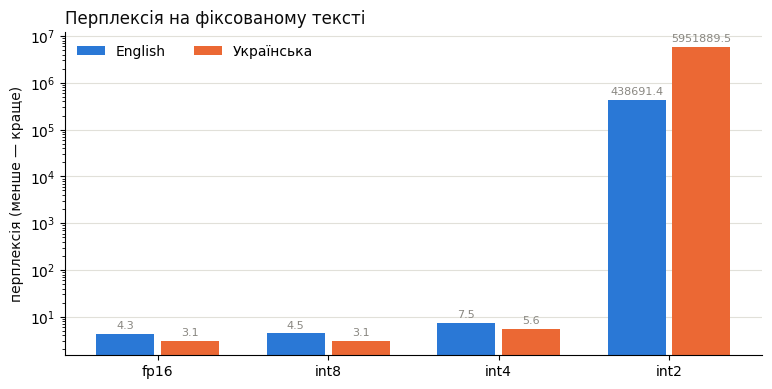

In [ ]:
LANG_COLORS = {"English": "#2a78d6", "Українська": "#eb6834"}
INK, MUTED, GRID = "#0b0b0b", "#898781", "#e1e0d9"

variants = list(records)
x = np.arange(len(variants))
width = 0.38

fig, ax = plt.subplots(figsize=(9, 4.2))
for i, lang in enumerate(PPL_TEXT):
    values = summary[f"перплексія, {lang}"].values
    bars = ax.bar(x + (i - 0.5) * width, values, width - 0.04, color=LANG_COLORS[lang], label=lang)
    ax.bar_label(bars, labels=[f"{v:.1f}" for v in values], fontsize=8, color=MUTED, padding=2)
ax.set_yscale("log")
ax.set_xticks(x, variants)
ax.set_ylabel("перплексія (менше — краще)", color=INK)
ax.set_title("Перплексія на фіксованому тексті", loc="left", color=INK)
ax.legend(frameon=False, ncols=2, loc="upper left")
ax.grid(axis="y", color=GRID, linewidth=0.8)
ax.set_axisbelow(True)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
plt.show()

Переклади всіх варіантів поруч з еталоном:

In [ ]:
translations = pd.DataFrame({"еталон": [ref for _, ref in TRANSLATION]}, index=[src for src, _ in TRANSLATION])
for name, r in records.items():
    translations[name] = r["переклади"]
translations

,еталон,fp16,int8,int4,int2
The meeting has been moved to Thursday at three o'clock.,Зустріч перенесли на четвер на третю годину.,"<think>\nOkay, the user wants me to translate ...","<think>\nOkay, the user wants me to translate ...",<think>\n</think>\n\nВідмітка була змінена на ...,Kö良ça良良良良良良良良良良良良良良良良良良良良良良良良良良良良良良良良良良良良良良良良良...
Please send me the report by the end of the day.,"Будь ласка, надішліть мені звіт до кінця дня.","<think>\nOkay, the user wants me to translate ...","<think>\nOkay, the user wants me to translate ...","<think>\nOkay, let's tackle this translation. ...",çaçaçaçaçaçaçaçaçaçaçaçaçaçaçaçaçaçaçaçaçaçaça...
The library is closed on Sundays and public holidays.,Бібліотека не працює в неділю та у святкові дні.,"<think>\nOkay, the user wants me to translate ...","<think>\nOkay, the user wants me to translate ...","<think>\nOkay, so the user wants me to transla...",çaçaçaça Nelçaçaçaçaçaçaçaçaçaçaça_cc_lpancias...
"Our team fixed the bug, but the tests are still failing.","Наша команда виправила помилку, але тести все ...","<think>\nOkay, the user wants me to translate ...","<think>\nOkay, the user wants me to translate ...",<think>\n</think>\n\nВсього наша команда відре...,çaçaçaçaçaçaçaçaçaçaçaçaçaçaçaçaçaçaçaçaçaça/d...
"It is going to rain tomorrow, so take an umbrella.","Завтра буде дощ, тож візьміть парасольку.","<think>\nOkay, the user wants me to translate ...","<think>\nOkay, the user wants me to translate ...","<think>\nOkay, let's tackle this translation. ...",çaçaçaçaçaçaçaçaçaçaçaçaçaçaçaçaçaçaçaçaçaçaça...
"The new model is smaller, but it answers almost as well as the old one.","Нова модель менша, але відповідає майже так са...","<think>\nOkay, the user wants me to translate ...","<think>\nOkay, the user wants me to translate ...","<think>\nOkay, let's tackle this translation. ...",çaçaçaçaçaçaçaça良ça良ça良ça良良良良良良良良良良良良良良良良良良良良良...
I would like to book a table for two for seven o'clock tonight.,Я хотів би забронювати столик на двох на сьому...,"<think>\nOkay, the user wants me to translate ...","<think>\nOkay, the user wants me to translate ...",<think>\n</think>\n\nЯ бажаю забічь таблі для ...,田田 rz rz rz rz rz л л rz_lp_lp_lp л rz_lp_lp_l...
The price includes breakfast and free Wi-Fi.,У вартість входять сніданок і безкоштовний Wi-Fi.,"<think>\nOkay, the user wants me to translate ...","<think>\nOkay, the user wants me to translate ...","<think>\nOkay, let's tackle this translation. ...",çaçaanelaanela.pg.pg.pg.pg.pg.pg.pgça.pgçaanel...
Students must submit their lab work before the deadline.,Студенти мають здати лабораторну роботу до кін...,"<think>\nOkay, the user wants me to translate ...","<think>\nOkay, the user wants me to translate ...","<think>\nOkay, let's tackle this translation. ...",çaçaçaçaçaçaçaçaçaçaça磊磊_cnçaça磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊...
"If the server does not respond, restart it and check the logs.","Якщо сервер не відповідає, перезапустіть його ...","<think>\nOkay, the user wants me to translate ...","<think>\nOkay, the user wants me to translate ...",<think>\n</think>\n\nЯкби сервер не відповідал...,ść pró良良良良良良良良良良良良良良良良良良良良良天上良良良天上天上天上天上ancias...


### 2.5. Сліпе порівняння: fp16 проти int4

Автоматичні метрики показали, наскільки int4 відрізняється від fp16 у числах. Тепер перевірмо очима — так, як це роблять оцінювачі-люди: для кожного запиту показуємо дві відповіді, fp16 та int4, **у випадковому порядку й без підписів**. Ваше завдання — обрати кращу.

In [ ]:
rng = np.random.default_rng(0)
BLIND_ORDER = [rng.permutation(["fp16", "int4"]) for _ in GEN_PROMPTS]

for i, prompt in enumerate(GEN_PROMPTS):
    display(Markdown(f"---\n#### Запит {i + 1}: {prompt}"))
    for label, name in zip("AB", BLIND_ORDER[i]):
        display(Markdown(f"**Відповідь {label}:**\n\n{records[name]['генерації'][i]}"))

---
#### Запит 1: Напиши короткий лист викладачеві з проханням перенести здачу лабораторної роботи на тиждень через хворобу.

**Відповідь A:**

<think>
Okay, the user wants a short letter to a professor asking to move the lab report submission to a week later due to illness. Let me start by understanding the key elements here.

First, the letter needs to be concise. It should include the student's name, the professor's name, the course, the original submission date, and the new date. The main request is to move the deadline to a week later because of illness. 

I should make sure to express the request politely and clearly. Maybe start with a greeting, state the purpose, mention the reason, and offer to provide any necessary documentation. Also, it's important to mention that the student is available to discuss the situation if needed.

I need to check for any specific formatting requirements, like the date, subject line, and closing. The tone should be respectful and professional. Avoid any technical jargon, keep it simple. Let me structure it step by step: subject line, greeting, body paragraphs with the request and

**Відповідь B:**

<think>
Okay, so I need to write a short list to a lecturer asking to transfer a lab assignment to a week through disease. Let me think about how to approach this.

First, the user wants a concise list. They might need to explain why the assignment was not done properly. Maybe the assignment was done on a week through disease, but now it's not. So, the request is to transfer the assignment to a week through disease.

Wait, maybe the original assignment was done on a week through disease, but now it's not. So, the user wants to transfer the assignment to a week through disease. But that's a bit confusing. Maybe the assignment was done on a week through disease, but now it's not, so they want to transfer it again?

Alternatively, maybe the user is asking to transfer the assignment to a week through disease, but the assignment was done on a week through disease. So, the request is to transfer the assignment to a week through disease again

---
#### Запит 2: Поясни студентові першого курсу в 3–4 реченнях, що таке квантизація нейромережі.

**Відповідь A:**

<think>
Okay, the user wants me to explain what quantization of a neural network to first-year students in 3-4 sentences. Let me start by recalling what quantization is. It's a technique to reduce the number of bits used to represent numbers, which helps in making models smaller and faster. But I need to make sure it's clear for students.

First, I should define quantization as reducing the precision of the weights and activations. Then mention that this is done to save memory and computation. Maybe also touch on how it affects model performance, like possible trade-offs between accuracy and efficiency. Need to keep it simple and concise. Let me check if I'm missing any key points. Oh, right, it's commonly used in models like MobileNet or EfficientNet. But since it's for students, maybe avoid specific examples unless necessary. Make sure each sentence is a clear point without jargon. Alright, that should cover it.
</think>

Квантизація

**Відповідь B:**

<think>
Okay, let me try to explain this to a student. So, the question is about what quantization of a neural network is. I need to make it in 3-4 sentences. 

First, I should define what quantization is. Maybe it's about using smaller numbers to represent data. Then, why is it important? Maybe to save memory and compute. And what does it do to the network? It might reduce precision but not affect performance. 

Wait, but I need to check if that's accurate. Quantization in neural networks is about using fewer bits to represent weights and activations. It saves memory and might be faster, but it can reduce precision. However, some networks might use it to make them more efficient. 

So, the three sentences could be: Quantization is a technique that uses smaller numbers to represent data in neural networks. It saves memory and compute resources by reducing precision. However, it can affect performance by lowering precision, but some networks use

... (5 outputs left out)

**Відповідь B:**

<think>
Okay, the user wants a 5-day plan for preparing for a programming exam. Let me start by breaking down what a programming exam typically involves. They probably need to cover key topics, practice coding, and review concepts. 

First day should be about understanding the exam structure. I need to outline the topics they'll cover. Maybe start with basics like variables, data types, control structures. Then move to functions, loops, and conditionals. Oh, and maybe some algorithms or data structures. But the user might not have specified the exam's focus, so I should keep it general.

Second day could be on problem-solving techniques. Practice coding exercises, maybe using platforms like LeetCode or HackerRank. Also, time management is important. They might need to practice under time constraints. Including a section on debugging and testing would be good.

Third day might focus on more advanced topics. Functions, arrays, objects, maybe some OOP concepts. Also, reviewing common errors and best practices

---
#### Запит 5: Write a Python function that checks whether a string is a palindrome.

**Відповідь A:**

<think>
Okay, I need to write a Python function that checks if a string is a palindrome. Hmm, a palindrome is a string that reads the same forwards and backwards. So, how do I check that?

Wait, maybe I can use the reverse() method. Oh right! Because if the string is a palindrome, reversing it should give the same string. So, the function can check if the string equals its reverse.

But wait, what about cases where the string is empty? Or has some characters? Oh right, the reverse method would handle those. But maybe I need to handle some edge cases.

Wait, the function should be named something like is_palindrome or check_pal. Let me think about the code structure.

So, the function would take a string as input. Then, check if the string equals the reverse of the string. But how to reverse the string? Using [::-1] which reverses the string. So, the code would be something like:

def is

**Відповідь B:**

<think>
Okay, I need to write a Python function that checks if a string is a palindrome. Hmm, a palindrome is a string that reads the same forwards and backwards. So, like "madam" or "racecar". 

First, I should think about how to compare the string with its reverse. Oh right, one way is to reverse the string and check if it's equal to the original. But wait, what about case sensitivity? Like, if the input is "Racecar", it's not a palindrome because of the uppercase and lowercase letters. So maybe the function should ignore case and punctuation? Or maybe the problem assumes that the input is a simple string without special characters? The question doesn't specify, so maybe I should handle case insensitivity.

Wait, the problem says "a string", so maybe the function should check if the string is a palindrome, considering case. But sometimes people want to ignore case. Let me think. The user didn't specify, but maybe

Для кожного запиту запишіть **"A"** або **"B"** — яка відповідь краща, або **"="**, якщо однакові за якістю. Потім запустіть наступну клітинку, щоб дізнатися, де була яка модель.

In [ ]:
VOTES = {1: "A", 2: "B", 3: "B", 4: "A", 5: "="}

In [ ]:
if all(v in ("A", "B", "=") for v in VOTES.values()):
    rows = []
    for i, vote in VOTES.items():
        order = dict(zip("AB", BLIND_ORDER[i - 1]))
        rows.append({"запит": GEN_PROMPTS[i - 1], "A": order["A"], "B": order["B"],
                     "ваш вибір": "однаково" if vote == "=" else order[vote]})
    display(pd.DataFrame(rows))
    choices = [r["ваш вибір"] for r in rows]
    print(f"fp16 краща: {choices.count('fp16')}, int4 краща: {choices.count('int4')}, однаково: {choices.count('однаково')}")
else:
    print('Заповніть VOTES значеннями "A", "B" або "=" для всіх 5 запитів.')

,запит,A,B,ваш вибір
0,Напиши короткий лист викладачеві з проханням п...,fp16,int4,fp16
1,Поясни студентові першого курсу в 3–4 реченнях...,fp16,int4,int4
2,Explain in three sentences why the sky is blue.,fp16,int4,int4
3,Склади план підготовки до іспиту з програмуван...,int4,fp16,int4
4,Write a Python function that checks whether a ...,int4,fp16,однаково


fp16 краща: 1, int4 краща: 3, однаково: 1


### 2.6. Відповіді всіх варіантів

Тепер, коли сліпе порівняння зроблено, — відповіді всіх варіантів з підписами, включно з int8 та int2. Еталону тут немає, тож читаємо самі.

In [ ]:
for i, prompt in enumerate(GEN_PROMPTS):
    display(Markdown(f"---\n#### Запит {i + 1}: {prompt}"))
    for name, r in records.items():
        display(Markdown(f"**{name}:**\n\n{r['генерації'][i]}"))

---
#### Запит 1: Напиши короткий лист викладачеві з проханням перенести здачу лабораторної роботи на тиждень через хворобу.

**fp16:**

<think>
Okay, the user wants a short letter to a professor asking to move the lab report submission to a week later due to illness. Let me start by understanding the key elements here.

First, the letter needs to be concise. It should include the student's name, the professor's name, the course, the original submission date, and the new date. The main request is to move the deadline to a week later because of illness. 

I should make sure to express the request politely and clearly. Maybe start with a greeting, state the purpose, mention the reason, and offer to provide any necessary documentation. Also, it's important to mention that the student is available to discuss the situation if needed.

I need to check for any specific formatting requirements, like the date, subject line, and closing. The tone should be respectful and professional. Avoid any technical jargon, keep it simple. Let me structure it step by step: subject line, greeting, body paragraphs with the request and

**int8:**

<think>
Okay, the user wants a short letter to a professor asking to move the lab report submission to a week later due to illness. Let me start by understanding the key elements here.

First, the letter needs to be concise. It should include the student's name, the professor's name, the course, the original submission date, and the new date. The main request is to move the deadline to a week later. The student should explain the reason, which is illness, and express gratitude.

I need to make sure the tone is polite and respectful. The student should mention the illness, perhaps specify the date, and ask for the flexibility. Also, include a thank you for the understanding. Let me check if there are any specific details the user might have missed. Since they didn't mention any, I'll keep it general.

Avoid any markdown, just plain text. Use formal language but keep it friendly. Maybe start with "Уважаючий [Препод

**int4:**

<think>
Okay, so I need to write a short list to a lecturer asking to transfer a lab assignment to a week through disease. Let me think about how to approach this.

First, the user wants a concise list. They might need to explain why the assignment was not done properly. Maybe the assignment was done on a week through disease, but now it's not. So, the request is to transfer the assignment to a week through disease.

Wait, maybe the original assignment was done on a week through disease, but now it's not. So, the user wants to transfer the assignment to a week through disease. But that's a bit confusing. Maybe the assignment was done on a week through disease, but now it's not, so they want to transfer it again?

Alternatively, maybe the user is asking to transfer the assignment to a week through disease, but the assignment was done on a week through disease. So, the request is to transfer the assignment to a week through disease again

**int2:**

hel helłow heliczłow hel hel钟 hel hel hel钟łowłowłow钟钟łowłowłowłowłowłowłowłow钟钟钟钟钟钟钟钟钟钟钟钟钟钟钟钟钟钟钟钟钟钟 время钟钟钟钟钟钟钟钟钟钟钟钟钟钟钟钟钟钟钟钟钟钟钟钟ça钟ça钟钟钟çaçaçaça钟钟钟çaça钟钟钟çaçaッッッッッッッッッçaçaçaçaçaçaçaçaçaçaçaçaçaçaçaçaça :

ッ :

çaçaçaçaçaçaçaçaçaçaçaçaçaçaçaçaçaçaçaçaçaçaçaçaçaçaçaçaçaçaçaçaçaçaçaçaçaçaçaçaçaçaçaçaçaçaçaçaçaçaçaçaçaçaçaçaçaçaçaCallbacks_cc_cc_cc_cc_cc_cc_cc_cc_cc_cc_cc_cc_cc_cc_cc_cc_cc_cc

---
#### Запит 2: Поясни студентові першого курсу в 3–4 реченнях, що таке квантизація нейромережі.

... (15 outputs left out)

**fp16:**

<think>
Okay, I need to write a Python function that checks if a string is a palindrome. Hmm, a palindrome is a string that reads the same forwards and backwards. So, like "madam" or "racecar". 

First, I should think about how to compare the string with its reverse. Oh right, one way is to reverse the string and check if it's equal to the original. But wait, what about case sensitivity? Like, if the input is "Racecar", it's not a palindrome because of the uppercase and lowercase letters. So maybe the function should ignore case and punctuation? Or maybe the problem assumes that the input is a simple string without special characters? The question doesn't specify, so maybe I should handle case insensitivity.

Wait, the problem says "a string", so maybe the function should check if the string is a palindrome, considering case. But sometimes people want to ignore case. Let me think. The user didn't specify, but maybe

**int8:**

<think>
Okay, I need to write a Python function that checks if a string is a palindrome. Hmm, a palindrome is a string that reads the same forwards and backwards. So, like "madam" or "racecar". 

First, I should think about how to compare the string with its reverse. Oh right, one way is to reverse the string and check if it's equal to the original. But wait, what about case sensitivity? Like, if the input is "Racecar", it's not a palindrome because of the uppercase and lowercase letters. So maybe the function should ignore case and punctuation? Or maybe the problem assumes that the input is a simple string without special characters? The question doesn't specify, but maybe the standard approach is to compare the string with its reverse, ignoring case and non-alphanumeric characters? Or maybe the function is supposed to check if the string is a palindrome in the standard way, considering case and letters only.

Wait, the problem says "a

**int4:**

<think>
Okay, I need to write a Python function that checks if a string is a palindrome. Hmm, a palindrome is a string that reads the same forwards and backwards. So, how do I check that?

Wait, maybe I can use the reverse() method. Oh right! Because if the string is a palindrome, reversing it should give the same string. So, the function can check if the string equals its reverse.

But wait, what about cases where the string is empty? Or has some characters? Oh right, the reverse method would handle those. But maybe I need to handle some edge cases.

Wait, the function should be named something like is_palindrome or check_pal. Let me think about the code structure.

So, the function would take a string as input. Then, check if the string equals the reverse of the string. But how to reverse the string? Using [::-1] which reverses the string. So, the code would be something like:

def is

**int2:**

н н́́́́́́́ćivirt良良良良良良良良良良良ça良люблюблюблюблюблюблюб务люблюб务磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊良磊磊良磊良良良良磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊

In [ ]:
word = 'трансформер'
for text in (word, ' ' + word):
    ids = tokenizer(text, add_special_tokens=False).input_ids
    print(repr(text), '->', [tokenizer.decode([i]) for i in ids], '| токенів:', len(ids))
print('Насправді літер «р»:', word.count('р'))

spaced = ' '.join(word)
ids = tokenizer(spaced, add_special_tokens=False).input_ids
print('Через пробіли:', [tokenizer.decode([i]) for i in ids])

r = chat(INSTRUCT_MODEL, 'Скільки разів літера «р» трапляється тут: ' + spaced + ' ?')
print(r['message']['content'])

'трансформер' -> ['т', 'ран', 'с', 'форм', 'ер'] | токенів: 5
' трансформер' -> [' т', 'ран', 'с', 'форм', 'ер'] | токенів: 5
Насправді літер «р»: 3
Через пробіли: ['т', ' р', ' а', ' н', ' с', ' ф', ' о', ' р', ' м', ' е', ' р']
Щоб визначити, скільки разів літера **«р»** трапляється в слові **«трансформер»**, зробимо так:

Слово: **трансформер**

Розбілем його на літери:

**т, р, а, н, с, ф, о, р, м, е, р**

Тепер підрахуємо кількість відповідних літер **«р»**:

- **р** — 1 раз  
- **р** — 2 раз  
- **р** — 3 раз

**Всього: 3 рази**

**Відповідь: 3**


In [ ]:
rows = []
for i, (src, ref) in enumerate(TRANSLATION):
    hyp = records['fp16']['переклади'][i]
    c = chrf.compute(predictions=[hyp], references=[[ref]])['score']
    b = bleu.compute(predictions=[hyp], references=[[ref]])['score']
    rows.append({'речення': src, 'еталон': ref, 'модель': hyp, 'chrF': round(c, 1), 'BLEU': round(b, 1)})
sent = pd.DataFrame(rows)
sent['різниця'] = sent['chrF'] - sent['BLEU']
display(sent.sort_values('різниця', ascending=False))

,речення,еталон,модель,chrF,BLEU,різниця
3,"Our team fixed the bug, but the tests are stil...","Наша команда виправила помилку, але тести все ...","<think>\nOkay, the user wants me to translate ...",19.5,1.3,18.2
9,"If the server does not respond, restart it and...","Якщо сервер не відповідає, перезапустіть його ...","<think>\nOkay, the user wants me to translate ...",14.0,1.2,12.8
4,"It is going to rain tomorrow, so take an umbre...","Завтра буде дощ, тож візьміть парасольку.","<think>\nOkay, the user wants me to translate ...",13.8,1.2,12.6
6,I would like to book a table for two for seven...,Я хотів би забронювати столик на двох на сьому...,"<think>\nOkay, the user wants me to translate ...",11.3,0.6,10.7
8,Students must submit their lab work before the...,Студенти мають здати лабораторну роботу до кін...,"<think>\nOkay, the user wants me to translate ...",10.4,0.6,9.8
5,"The new model is smaller, but it answers almos...","Нова модель менша, але відповідає майже так са...","<think>\nOkay, the user wants me to translate ...",5.2,0.6,4.6
7,The price includes breakfast and free Wi-Fi.,У вартість входять сніданок і безкоштовний Wi-Fi.,"<think>\nOkay, the user wants me to translate ...",4.9,0.6,4.3
1,Please send me the report by the end of the day.,"Будь ласка, надішліть мені звіт до кінця дня.","<think>\nOkay, the user wants me to translate ...",3.5,0.6,2.9
0,The meeting has been moved to Thursday at thre...,Зустріч перенесли на четвер на третю годину.,"<think>\nOkay, the user wants me to translate ...",2.9,0.5,2.4
2,The library is closed on Sundays and public ho...,Бібліотека не працює в неділю та у святкові дні.,"<think>\nOkay, the user wants me to translate ...",0.4,0.5,-0.1


In [ ]:
few_shot = (
    'Питання: Яка столиця Німеччини?\nВідповідь: Берлін\n\n'
    'Питання: Яка столиця Італії?\nВідповідь: Рим\n\n'
    'Питання: Яка столиця Франції?\nВідповідь:'
)
out = generate_raw(BASE_MODEL, few_shot, max_tokens=8)
print(repr(out))
print('Відповідь:', out.strip().split('\n')[0])

print(generate_raw(BASE_MODEL, 'Столиця Франції — це місто', max_tokens=6))

' Паризька\n\nПитан'
Відповідь: Паризька
, яке має вели


In [ ]:
tasks = [
    ('У Петра було 24 цукерки. Третину він віддав сестрі, потім купив ще 8, а половину того, що вийшло, зʼїв. Скільки цукерок у нього залишилось?', '12'),
    ('Потяг виїхав о 14:20 і був у дорозі 3 години 55 хвилин. О котрій він прибув?', '18:15'),
    ('Іра старша за Олю на 3 роки, Оля старша за Тараса на 5 років. Тарасові 10. Скільки років Ірі?', '18'),
    ('Скільки буде 17 × 23?', '391'),
]
for q, right in tasks:
    print('#', q[:70], '| правильно:', right)
    for think in (False, True):
        m = chat(INSTRUCT_MODEL, q, think=think)['message']['content']
        print('   think=%s ->' % think, m.strip().replace('\n', ' ')[-200:])

# У Петра було 24 цукерки. Третину він віддав сестрі, потім купив ще 8,  | правильно: 12
   think=False ->       Північна частина — це:      $$    \frac{24}{2} = 12    $$      Значить, Петр з’їв **12 цукерок**.  5. **Залишилося:**      $$    24 - 12 = 12    $$  **Відповідь:**   Петр залишив **12 цукерок**.
   think=True ->  16 + 8 = 24    $$   4. **Після з’їння половини цих цукерок:**      $$    \frac{1}{2} \times 24 = 12    $$      Залишилося:      $$    24 - 12 = 12    $$    Отже, у Петра залишилося:  $$ \boxed{12} $$
# Потяг виїхав о 14:20 і був у дорозі 3 години 55 хвилин. О котрій він п | правильно: 18:15
   think=False -> 5 хвилин**.  Тепер додамо 235 хвилин до 14:20.  - 235 хвилин = 3 години 55 хвилин. - 14:20 + 3 години = **17:20**. - 17:20 + 55 хвилин = **17:75**, або **18:15**.  **Відповідь: потяг прибув о 18:15.**
   think=True -> 
# Іра старша за Олю на 3 роки, Оля старша за Тараса на 5 років. Тарасові | правильно: 18
   think=False -> ### Крок 2: Знайти вік Іри  Іра старша

In [34]:
m16 = AutoModelForCausalLM.from_pretrained(MODEL_ID, dtype=DTYPE, device_map=DEVICE)
print('fp16-модель завантажено, GB:', torch.cuda.memory_allocated() / 1e9)

Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]

fp16-модель завантажено, GB: 3.449684992


In [37]:
import random
words = PPL_TEXT['English'].replace(',', '').replace('.', '').replace(':', '').split()
random.seed(0)
shuffled = words.copy()
random.shuffle(shuffled)
random_words = random.choices(sorted(set(words)), k=len(words))

print('Осмислений текст :', round(perplexity(m16, PPL_TEXT['English']), 1))
print('Перемішані слова :', round(perplexity(m16, ' '.join(shuffled)), 1))
print('Випадкові слова  :', round(perplexity(m16, ' '.join(random_words)), 1))

Осмислений текст : 4.3
Перемішані слова : 425.7
Випадкові слова  : 758.2


In [36]:
print('m16 є:', 'm16' in globals())
print('Памʼять зайнята, GB:', torch.cuda.memory_allocated() / 1e9)

m16 є: True
Памʼять зайнята, GB: 3.449684992


In [35]:
n = sum(p.numel() for p in m16.parameters())
print('Параметрів: %.2f млрд' % (n / 1e9))
print('fp16, лише ваги (P x 16 / 8): %.2f GB' % (n * 2 / 1e9))
print('з запасом 20%%: %.2f GB' % (n * 2 * 1.2 / 1e9))

Параметрів: 1.72 млрд
fp16, лише ваги (P x 16 / 8): 3.44 GB
з запасом 20%: 4.13 GB


In [ ]:
print(torch.cuda.get_device_capability())

(7, 5)


1. Модель бачить слово «трансформер» як 5 токенів: «т», «ран», «с», «форм», «ер». Літери всередині токенів вона напряму не бачить, тому підрахунок спирається на пам'ять про токени, а не на послідовність літер. Без міркувань модель відповіла 1, з міркуваннями 2. У міркуванні видно, де саме помилка: модель випсала літери з помилкою (пропустила «ф» і вставила зайві «т» і «о»), і підрахунок став хибним. Коли між літерами стоять пробіли, кожна літера стає окремим токеном, і модель відповідає правильно: 3. Правильна кількість «р» у слові «трансформер» — три (т-р-а-н-с-ф-о-р-м-е-р... тобто позиції 2, 8 і 11).

2. Від fp16 до int8 перплексія майже не змінюється: англійська 2.67 → 2.67, українська 2.40 → 2.40. Метрики перекладу навіть трохи зростають (chrF 55.22 → 58.25, BLEU 23.71 → 26.17). На int4 перплексія англійської зростає до 2.81 (приблизно ×1.05), української до 2.76 (×1.15), chrF майже без змін (55.34), BLEU трохи вищий (29.79). На int2 перплексія англійської 60 091.86 (приблизно ×22 500), української 34 451 480, chrF 0.19, BLEU 0.12. Найбільший стрибок між int4 і int2: перплексія зростає приблизно на чотири порядки, а метрики падають майже до нуля. Причина в кількості рівнів: int4 має 16 рівнів на вагу, int2 лише 4.

3. Перплексія зростає для обох мов, але для української помітніше: на int4 приблизно на 15%, для англійської приблизно на 5%. На int2 обидві мови руйнуються, українська сильніше (приблизно у 14 мільйонів разів проти 22 500 для англійської). Це узгоджується зі слайдом «Де може просідати якість при квантизації»: українська деградує швидше. Висновок попередній, бо перевірено один короткий текст на кожну мову.

4. У сліпому порівнянні на 5 запитах вибрано: fp16 — 1 раз, int4 — 3 рази, однаково — 1 раз. Автоматичні метрики для fp16 і int4 майже однакові (chrF 55.22 і 55.34, перплексія англійської 2.67 і 2.81), а BLEU навіть вищий в int4 (29.79 проти 23.71). Тобто вибір int4 частіше відповідає метрикам: різниці майже немає, і якість int4 не виглядає гіршою. Розбіжність можлива там, де метрики не змінилися, але голос віддано за одну з моделей. Для int2 сліпого порівняння не було, тому там розбіжності немає.

5. Приклад: «The meeting has been moved to Thursday at three o’clock.» Еталон «Зустріч перенесли на четвер на третю годину» є буквальним перекладом і звучить незвично. Модель fp16 написала «Зустріч була перенесена на четвер, о 15 годин». Зміст той самий, слова інші. chrF 49.9, BLEU 10.0, різниця 39.9 — найбільша в таблиці. BLEU реагує сильніше, бо рахує збіги слів і послідовностей із чотирьох слів, а тут майже жодна така послідовність не збігається. chrF рахує символи, тому збігаються корені «зустріч» і «четвер», і падіння менше. Інший приклад: «Students must submit their lab work before the deadline» (chrF 60.5, BLEU 23.4) теж правильний за змістом, але з іншими словами.

6. Памʼять: fp16 — 8.04 GB, int8 — 4.42 GB (у 1.8 раза менше), int4 — 2.73 GB (у 2.9 раза), int2 — 1.81 GB (у 4.4 раза). Не вдвічі та не вчетверо, бо квантизуються лише лінійні шари (приблизно 3.6 млрд параметрів), а ембединги (приблизно 0.4 млрд, або 0.8 GB у fp16) лишаються у 16 бітах. Крім того, кожен блок ваг має власний масштаб. Перевірка: 3.6 × 0.5 + 0.8 ≈ 2.6 GB для int4, а 3.6 × 0.25 + 0.8 ≈ 1.7 GB для int2. Це близько до виміряних значень. Генерація не прискорилась: tokens/s — 17.01 для fp16, 5.87 для int8, 2.89 для int4 і 2.96 для int2. У ноутбуці сказано, що на T4 кастомні CUDA-ядра Quanto не компілюються, тому ваги розпаковуються у 16 біт на PyTorch перед кожним множенням. Це коштує більше, ніж економія на читанні памʼяті. Квантизація економить памʼять, а не час.

7. Base-модель (Qwen3-1.7B-Base, квантована Q4_K_M) навчена лише продовжувати текст. «Яка столиця Франції?» схоже на початок вікторини, тому природне продовження — нові питання. Промпт із прикладами (few-shot) вирішує це, бо модель продовжує шаблон «Відповідь:» і дає відповідь в одному рядку. Модель відповіла «Паризька». Шаблон спрацював, але граматично форма неправильна (правильно «Париж»). Для малої квантованої моделі це очікувана вада. Друге запитання без шаблону «Столиця Франції — це місто» дало «, яке має вели...», тобто модель не завершує речення коректно.

8. Без міркувань модель згенерувала 252 токени за 2.2 с. З міркуваннями 569 токенів за 5.0 с. Тобто міркування зайняло приблизно у 2.3 раза більше токенів і часу. Модель міркує англійською, бо приклади для режиму міркування в навчанні переважно англійською, і англійською модель працює найсильніше. Фінальну відповідь вона дає українською, бо її навчали відповідати мовою запиту.

9. На всіх чотирьох задачах (цукерки, потяг, Іра і Оля, 17 × 23) обидва режими дали правильні відповіді: 12, 18:15, 18 і 391. Тобто в цьому наборі міркування не дало переваги. Щоб показати ефект, потрібна задача з більшою кількістю кроків. Наприклад: «У магазині було 120 книжок. Першого дня продали 25%, другого — третину решти, третього — ще 10 книжок. Скільки лишилось?» (правильно 50). Якщо запустити її в тій самій клітинці і вставити вивід, можна порівняти відповіді. Поки що відповідь така: знайдено лише те, що міркування не дало переваги на простих задачах.

10. temperature: 0 означає, що модель завжди вибирає найімовірніший токен, тож однаковий запит дає однакову відповідь. seed: 1 фіксує генератор випадкових чисел на випадок, якщо десь лишилась випадковість. Разом вони роблять запуски відтворюваними, тож різниця між режимами або моделями є справжньою, а не шумом семплінгу. Застереження: на GPU можуть бути дрібні розбіжності через порядок операцій із плаваючою комою.

11. T4 має архітектуру Turing з обчислювальною можливістю 7.5, тобто get_device_capability() повертає (7, 5). Апаратна підтримка bf16 з'явилася в Ampere (можливість 8.0 і вище). Тому на T4 вибираємо fp16: bf16 там або не працює, або працює повільно. У ноутбуці перевірка get_device_capability()[0] < 8 вмикає запасну розпаковку ваг на чистому PyTorch. Компроміс: bf16 має діапазон як у fp32 і рідко переповнюється, а fp16 точніша, але максимальне значення лише 65 504. Qwen3 навчали в bf16, тож у fp16 теоретично можливе переповнення. На практиці модель у fp16 працювала коректно.

12. Qwen3-4B-Instruct-2507 має 4.02 млрд параметрів: приблизно 3.6 млрд у шарах і 0.4 млрд в ембедингах. За формулою з лекції M ≈ P × Q / 8 × (1 + O) для fp16 (Q = 16) і без запасу (O = 0) маємо 4.02 × 16 / 8 = 8.04 GB. З запасом 20% виходить 9.65 GB. У таблиці розділу 2.4 «памʼять моделі» для fp16 дорівнює 8.04 GB, тобто збігається з формулою без запасу, бо torch.cuda.memory_allocated() рахує лише ваги.

13. Перплексія — це експонента від середньої від'ємної логарифмічної ймовірності наступного токена. Інтуїтивно: скільки варіантів модель у середньому розглядає при виборі наступного токена. Мінімум дорівнює 1, менше — краще. Результати для fp16 моделі 4B: осмислений текст — 2.7, перемішані слова — 395.0, випадкові слова — 641.7. Без граматики і змісту наступне слово майже непередбачуване, модель розподіляє ймовірність між багатьма варіантами, і перплексія зростає приблизно у 150 разів. Порівнювати перплексію між мовами не можна: українські слова розбиваються на більше токенів, а тексти різні за змістом. Порівнювати можна лише на одному тексті для різних варіантів однієї моделі або відносне зростання.

14. Пік VRAM — 8.64 GB, памʼять моделі — 8.04 GB, різниця близько 0.6 GB. Крім ваг, під час роботи займають памʼять:

KV-кеш: 2 × 36 шарів × 8 KV-голів × 128 × 2 байти ≈ 144 KiB на токен. Для кількох сотень токенів це десятки мегабайтів, а для довгих контекстів стає суттєво більше.
Активації проміжних шарів.
Логіти: довжина послідовності × розмір словника (151 936), а при обчисленні перплексії ще й у fp32.
Тимчасові буфери. Для квантованих варіантів ваги тимчасово розпаковуються у fp16.

Пік більший за розмір ваг, але на коротких текстах різниця невелика.

15. Голоси: fp16 — 1, int4 — 3, однаково — 1. Із чотирьох ненульових порівнянь три на користь int4 і одне на користь fp16. Якщо обидві відповіді однаково ймовірні, шанс отримати 3 або більше з 4 випадково дорівнює 5/16 ≈ 31%. Це не статистично значуще. Щоб відрізнити 60% переваги від 50% з надійністю 95%, потрібно близько 200 пар без нічиї. Висновок з 5 порівнянь показує лише напрямок, але не доводить різниці.

16. Int2 ламає моделі повністю: відповіді складаються з повторів символів, випадкових латинських фрагментів і знаків пунктуації (наприклад, «takenosthawkhhhawkoft0houghth» або «fil}’sand ever0'f}’h’»). У перекладах з'являються китайські символи. Зв'язних речень не виходить, бо модель не відтворює граматичні конструкції.

Ознаки погіршення вже видно в int4 і частково в int8:

Зміна сенсу. «The library is closed on Sundays and public holidays» стало «Бібліотека відкрита тільки з 1 по 7», тобто протилежний зміст.
Неправильне слово. «I would like to book a table» стало «Я б хотів зареєструвати стіл», тоді як треба «забронювати». Fp16 цього не має.
Неправильна лексика. «The price includes breakfast» стало «Ціна включає початок дня» (int8 і int4), а fp16 написав «сніданок».
Неправильний предмет. «Take an umbrella» стало «візьміть засіб» (int4), а fp16 написав «парасольку».
Порушене узгодження. «The new model is smaller» стало «Новий модель менший» (int8 і int4), тоді як fp16 написав «Нова модель менша».

Важливо, що chrF і BLEU у int4 не гірші за fp16, тобто метрики цих помилок не виявляють. Перплексія при int4 зростає лише на 5–15%, тож перші ознаки проявляються саме в змісті і граматиці перекладів.

17. Порівняння 1.7B з 4B:

Перплексія fp16 на англійському тексті: 4.35 проти 2.67. Менша модель гірша.
Зростання від fp16 до int4: для англійської ×1.73 у 1.7B проти ×1.05 у 4B, для української ×1.81 проти ×1.15.
На int8 перплексія майже не змінюється в обох моделях.
На int2 обидві моделі руйнуються: англійська 438 691 у 1.7B і 60 092 у 4B.
Метрики перекладу в 1.7B значно нижчі вже у fp16: chrF 8.64 проти 55.22, BLEU 0.25 проти 23.71. Це властивість моделі, а не квантизації. chrF і BLEU у 1.7B навіть трохи зростають на int4 (10.10 і 0.58), тому порівнювати просадку за ними немає сенсу.

Висновок: квантизація сильніше б'є по меншій моделі. На int4 перплексія 1.7B зростає приблизно на 70%, а 4B — лише на 5%. Меншій моделі, ймовірно, бракує запасу, тож похибка округлення стає помітнішою.

18. Параметр OLLAMA_NUM_PARALLEL задає, скільки запитів одна завантажена модель обробляє одночасно. Кожен паралельний запит має свій контекст, тож потрібен окремий KV-кеш, і памʼять зростає. Більший паралелізм збільшує сумарну пропускну здатність за кількох клієнтів, але кожен окремий запит може генеруватися повільніше, бо ділить обчислення. У демо-ноутбуці цього параметра немає, тому відповідь теоретична.

19. Більшість сучасних моделей тренують у bf16, бо вона має той самий діапазон, що й fp32 (8 бітів експоненти). Великі моделі мають великі активації та градієнти, тому переповнення в fp16 (максимум 65 504) тут критичніше, ніж менша точність мантиси (7 бітів у bf16 проти 10 у fp16). Для тренування bf16 не потребує масштабування втрат (loss scaling), яке потрібне для fp16. Перетворення з fp32 у bf16 просте: достатньо відкинути частину мантиси, тому bf16 добре підтримується сучасним апаратним забезпеченням.

20. OpenAI задала стандарт API: запит до /v1/chat/completions з JSON-масивом повідомлень. Рантайми Ollama, llama.cpp (llama-server) і LM Studio реалізують той самий протокол, тому клієнт, написаний під OpenAI, працює з локальною моделлю лише після зміни base_url, наприклад http://localhost:11434/v1. Це дає змогу не переписувати код під кожен рантайм і замінити модель чи рантайм без змін у застосунку. ChatGPT — продукт OpenAI, а API — інтерфейс, через який розробники до нього звертаються. Протокол став де-факто стандартом, тому інші системи його теж підтримують.